# Лабораторная работа № 3. Линейная регрессия
**Сафиулин А. Ю. • БГУ, ФПМИ**

Цель — обучить парную и множественную линейные регрессии в Anaconda Jupyter Notebook и сравнить качество прогнозов на тестовых данных.

Линейная модель задаёт прогноз $\hat y = b_0 + \sum_j b_j x_j$. Метод наименьших квадратов подбирает коэффициенты, минимизируя сумму квадратов остатков на обучающей выборке. Коэффициент $b_j$ показывает изменение прогноза при увеличении соответствующего признака на единицу при остальных фиксированных признаках.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

lab_dir = Path.cwd()
if not (lab_dir / "data" / "cars.csv").is_file():
    lab_dir = lab_dir / "lab3"

data_dir = lab_dir / "data"
figures_dir = lab_dir / "figures"
outputs_dir = lab_dir / "outputs"
figures_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")

print(f"Python {sys.version.split()[0]}, окружение {Path(sys.prefix).name}")
print(f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}")

Python 3.11.16, окружение lab1_terminal
pandas 3.0.5, scikit-learn 1.9.0


## 1. Парная регрессия на наборе Cars

В наборе [Cars из R](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/cars.html) измерены скорость `speed` в милях в час и расстояние до остановки `dist` в футах. Наблюдения записаны в 1920-е годы. Служебный номер строки из CSV используется как индекс.

In [2]:
def audit(frame):
    print(f"Размерность: {frame.shape[0]} строк × {frame.shape[1]} столбцов")
    display(frame.head())
    display(pd.DataFrame({
        "Тип данных": frame.dtypes.astype(str),
        "Пропуски": frame.isna().sum(),
    }))


cars = pd.read_csv(data_dir / "cars.csv", index_col=0)
audit(cars)

Размерность: 50 строк × 2 столбцов


,speed,dist
rownames,,
1,4,2
2,4,10
3,7,4
4,7,22
5,8,16


,Тип данных,Пропуски
speed,int64,0
dist,int64,0


In [3]:
x_cars = cars[["speed"]]
y_cars = cars["dist"]
x_train, x_test, y_train, y_test = train_test_split(
    x_cars, y_cars, test_size=0.2, random_state=42
)
cars_model = LinearRegression().fit(x_train, y_train)
cars_pred = cars_model.predict(x_test)

slope = cars_model.coef_[0]
intercept = cars_model.intercept_
print(f"Train: {len(x_train)}, test: {len(x_test)}")
print(f"Наклон: {slope:.4f} фут/(миля/ч)")
print(f"Свободный член: {intercept:.4f} фут")
print(f"dist = {intercept:.4f} + {slope:.4f} × speed")

Train: 40, test: 10
Наклон: 3.6857 фут/(миля/ч)
Свободный член: -14.1339 фут
dist = -14.1339 + 3.6857 × speed


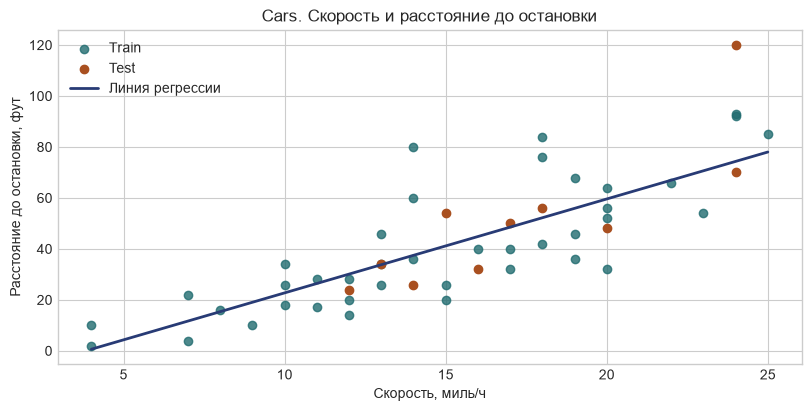

In [4]:
speed_grid = pd.DataFrame({
    "speed": np.linspace(x_cars["speed"].min(), x_cars["speed"].max(), 150)
})

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.scatter(x_train["speed"], y_train, color="#216C70", alpha=0.8, label="Train")
ax.scatter(x_test["speed"], y_test, color="#A95020", label="Test")
ax.plot(
    speed_grid["speed"], cars_model.predict(speed_grid),
    color="#283B75", linewidth=2, label="Линия регрессии",
)
ax.set(
    title="Cars. Скорость и расстояние до остановки",
    xlabel="Скорость, миль/ч", ylabel="Расстояние до остановки, фут",
)
ax.legend()
fig.savefig(figures_dir / "cars_regression.png", dpi=150)
plt.show()

## 2. Эксперименты с признаками Advertising

Набор [Advertising из ISL](https://www.statlearning.com/resources-first-edition) содержит расходы на рекламу (`TV`, `radio`, `newspaper`, тыс. долларов) и продажи (`sales`, тыс. единиц) для 200 рынков. Самый сильный одиночный признак определяем по модулю корреляции Пирсона с продажами на обучающих строках. Все три модели оцениваем на одинаковых тестовых строках.

In [5]:
advertising = pd.read_csv(data_dir / "Advertising.csv", index_col=0)
audit(advertising)

channels = ["TV", "radio", "newspaper"]
sales = advertising["sales"]
ad_train_ids, ad_test_ids = train_test_split(
    advertising.index, test_size=0.2, random_state=42
)
train_correlations = (
    advertising.loc[ad_train_ids, channels]
    .corrwith(sales.loc[ad_train_ids])
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
display(train_correlations.round(4).to_frame("r Пирсона на train"))

Размерность: 200 строк × 4 столбцов


,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


,Тип данных,Пропуски
TV,float64,0
radio,float64,0
newspaper,float64,0
sales,float64,0


,r Пирсона на train
TV,0.7689
radio,0.5924
newspaper,0.2379


In [6]:
experiments = {
    "A": train_correlations.index[:1].tolist(),
    "B": train_correlations.index[:2].tolist(),
    "C": channels,
}
ad_models = {}
ad_pred = pd.DataFrame({"actual": sales.loc[ad_test_ids]})
coefficients = []

for name, features in experiments.items():
    ad_x_train, ad_x_test, ad_y_train, ad_y_test = train_test_split(
        advertising[features], sales, test_size=0.2, random_state=42
    )
    assert ad_x_train.index.equals(ad_train_ids)
    assert ad_x_test.index.equals(ad_test_ids)
    model = LinearRegression().fit(ad_x_train, ad_y_train)
    ad_models[name] = model
    ad_pred[name] = model.predict(ad_x_test)
    coefficients.append({
        "Модель": name, "Признаки": " + ".join(features),
        "Train": len(ad_x_train), "Test": len(ad_x_test),
        "Intercept": model.intercept_, **dict(zip(features, model.coef_)),
    })

ad_coefficients = pd.DataFrame(coefficients).set_index("Модель")
display(ad_coefficients.round(4).fillna("—"))

,Признаки,Train,Test,Intercept,TV,radio,newspaper
Модель,,,,,,,
A,TV,160,40,7.1196,0.0465,—,—
B,TV + radio,160,40,3.0283,0.0447,0.1907,—
C,TV + radio + newspaper,160,40,2.9791,0.0447,0.1892,0.0028


## 3. Метрики на тестовых выборках

- **MAE** — среднее абсолютное отклонение в единицах целевой переменной.
- **MSE** — средний квадрат ошибки в квадрате единицы целевой переменной. Крупные ошибки вносят больший вклад.
- **R²** — $1 - \sum (y_i - \hat y_i)^2 / \sum (y_i - \bar y)^2$, где $\bar y$ — среднее фактических тестовых значений.

MAE и MSE сравниваем между вариантами Advertising. Для Cars они выражены в футах и квадратных футах, для Advertising — в тысячах единиц и квадрате этой единицы.

In [7]:
def test_metrics(dataset, model, features, actual, predicted):
    return {
        "Датасет": dataset, "Модель": model, "Признаки": " + ".join(features),
        "Размер теста": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    }


metrics = pd.DataFrame([
    test_metrics("Cars", "Парная", ["speed"], y_test, cars_pred),
    *[
        test_metrics("Advertising", name, features, ad_pred["actual"], ad_pred[name])
        for name, features in experiments.items()
    ],
])
display(metrics.round(4))

,Датасет,Модель,Признаки,Размер теста,MAE,MSE,R²
0,Cars,Парная,speed,10,11.0314,275.4290,0.6158
1,Advertising,A,TV,40,2.4444,10.2047,0.6767
2,Advertising,B,TV + radio,40,1.4443,3.1379,0.9006
3,Advertising,C,TV + radio + newspaper,40,1.4608,3.1741,0.8994


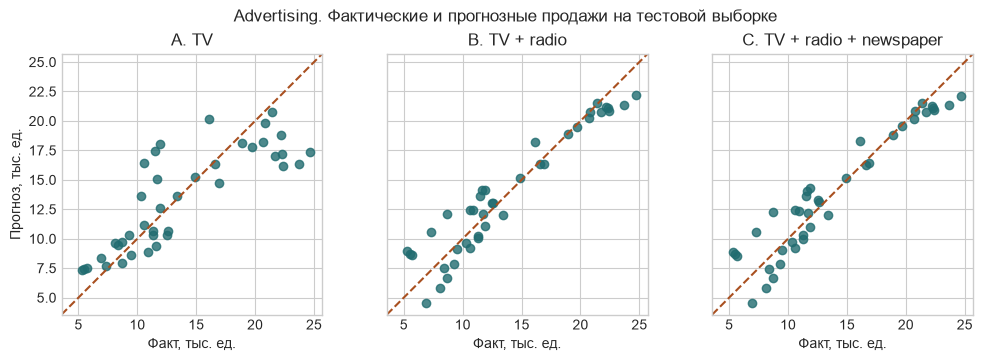

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained", sharex=True, sharey=True)
low, high = ad_pred.min().min() - 1, ad_pred.max().max() + 1
for ax, (name, features) in zip(axes, experiments.items()):
    ax.scatter(ad_pred["actual"], ad_pred[name], color="#216C70", alpha=0.8)
    ax.plot([low, high], [low, high], "--", color="#A95020")
    ax.set(
        title=f"{name}. {' + '.join(features)}",
        xlabel="Факт, тыс. ед.", xlim=(low, high), ylim=(low, high),
    )
    ax.set_aspect("equal")
axes[0].set_ylabel("Прогноз, тыс. ед.")
fig.suptitle("Advertising. Фактические и прогнозные продажи на тестовой выборке")
fig.savefig(figures_dir / "advertising_predictions.png", dpi=150)
plt.show()

In [9]:
metrics.to_csv(outputs_dir / "metrics.csv", index=False)
ad_coefficients.fillna("").to_csv(outputs_dir / "advertising_coefficients.csv")
pd.DataFrame({
    "speed": x_test["speed"], "actual": y_test, "predicted": cars_pred
}).sort_index().to_csv(outputs_dir / "cars_test_predictions.csv", index_label="row")
ad_pred.sort_index().to_csv(outputs_dir / "advertising_test_predictions.csv", index_label="row")
joblib.dump(ad_models["C"], outputs_dir / "advertising_model.joblib")

ad_metrics = metrics[metrics["Датасет"].eq("Advertising")].set_index("Модель")
best = ad_metrics["MSE"].idxmin()
print(f"Минимальный MSE среди моделей Advertising: {best}, {ad_metrics.at[best, 'MSE']:.4f}")
print(f"Снижение MAE при добавлении radio: {ad_metrics.at['A', 'MAE'] - ad_metrics.at['B', 'MAE']:.4f}")
print("Графики, таблицы прогнозов, метрики и модель C сохранены.")

Минимальный MSE среди моделей Advertising: B, 3.1379
Снижение MAE при добавлении radio: 1.0001
Графики, таблицы прогнозов, метрики и модель C сохранены.


## 4. Выводы

В Cars модель оценивает рост расстояния до остановки с увеличением скорости. Свободный член соответствует нулевой скорости за пределами наблюдений, поэтому физически его не интерпретируем. Вывод о качестве на тесте основан на 10 наблюдениях.

В Advertising добавление радио заметно уменьшило ошибки на одних и тех же тестовых строках. У модели B минимальные MAE (1,4443) и MSE (3,1379) и максимальный R² (0,9006). После добавления газет MAE и MSE немного выросли, а R² снизился до 0,8994. Модель C экспортирована для симулятора, чтобы управлять всеми тремя рекламными каналами. Коэффициенты описывают связи в этой выборке. По ним нельзя судить о причинном эффекте рекламы.